# La Liga Match Prediction

Predicting La Liga match outcomes (home win / draw / away win) and the most likely scoreline from historical match data, Elo ratings and scraped xG, benchmarked against bookmaker odds.

## Imports


In [1]:
# Standard library
import itertools
import sys  # lets us edit the module search path (next steps)
from pathlib import Path  # OS-independent paths, no hard-coded C:\... strings

# Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve

## Notebook setup

Reload edited `src/` modules automatically and make the repo root importable, so reusable code can live in `src/` instead of the notebook.


In [2]:
%load_ext autoreload
# Mode 2 = reload all modules (except excluded ones) before running each cell, so
# edits to src/*.py take effect without a kernel restart
%autoreload 2

In [3]:
# Walk up from the working directory (notebooks/ in VS Code) until we reach the
# folder that contains environment.yml: that is the repo root
REPO_ROOT = next(
    folder
    for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "environment.yml").exists()
)

# Put the repo root first on the import path so `from src... import ...` works.
# The check avoids adding a duplicate entry every time this cell is re-run.
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

print(f"Repo root: {REPO_ROOT}")

Repo root: c:\laliga-match-prediction


In [4]:
from src.cleaning import (
    add_season_columns,
    build_team_season_table,
    format_season,
    missing_pct_by_group,
    missing_value_summary,
)
from src.evaluation import forward_chaining_log_loss, score_probabilities
from src.features import (
    add_promoted_flag,
    add_rolling_averages,
    add_team_features,
    build_team_matches,
    latest_rolling_averages,
)
from src.models import (
    ODDS_COLUMNS,
    bookmaker_probabilities,
    make_goals_model,
    make_outcome_model,
    most_likely_scores,
    outcomes_from_scores,
    poisson_probabilities,
    predict_outcomes,
    score_matrices,
)
from src.plotting import set_season_xaxis
from src.team_names import MATCHES_NAME_FIXES

In [5]:
# One chart style for the whole notebook
sns.set_theme(
    style="whitegrid",
    rc={
        "axes.edgecolor": "#c3c2b7",
        "grid.color": "#e1e0d9",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "bold",
        "figure.dpi": 110,
    },
)

## Config / constants

All paths are built from `REPO_ROOT`, so the notebook runs from any clone without editing. `RANDOM_STATE` is the single seed used everywhere randomness appears, so results are reproducible.


In [6]:
# Data folders (raw = downloaded / scraped and never modified, processed = our outputs)
DATA_DIR = REPO_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

# Deliverables: Excel workbook, saved figures, predictions
OUTPUTS_DIR = REPO_ROOT / "outputs"

# Data-only workbook written by the notebook. The hand-built analysis lives in a separate file, so re-running never overwrites manual work
EXCEL_DATA_PATH = OUTPUTS_DIR / "laliga_data.xlsx"

# One seed for every train/test split, CV fold and model, for reproducible results
RANDOM_STATE = 42

# Rolling team features: Average of the previous ROLLING_WINDOW matches (about a quarter of a season), and only when at least ROLLING_MIN_PERIODS of them have the stat
ROLLING_WINDOW = 10
ROLLING_MIN_PERIODS = 5
ROLLING_COLUMNS = ["GoalsFor", "GoalsAgainst", "TargetFor", "TargetAgainst"]

# Seasons, by SeasonStart year. Modeling starts in 2007/08 (2006/07 is missing, so earlier seasons have gaps in their history). The last complete season is the test set, and everything before it is training data
FIRST_MODEL_SEASON = 2007
TEST_SEASON_START = 2025

# The columns that identify one match: a team can't host the same opponent twice on one day, so this combination must be unique
MATCH_KEY = ["Division", "MatchDate", "HomeTeam", "AwayTeam"]

# Divisions we use: La Liga, plus Segunda for promoted teams' pre-La Liga history
LALIGA_DIVISION = "SP1"
SEGUNDA_DIVISION = "SP2"
SPANISH_DIVISIONS = [LALIGA_DIVISION, SEGUNDA_DIVISION]

# The two columns holding team names in Matches.csv
TEAM_COLUMNS = ["HomeTeam", "AwayTeam"]

# Full-time goals: The targets of the scoreline model
FULL_TIME_GOAL_COLUMNS = ["FTHome", "FTAway"]

# Last fully played season: 2026/27 is in progress, so it is excluded from season-level EDA and kept for the prediction demo
LAST_COMPLETE_SEASON = 2025

# Saved charts for the README and the pitch
FIGURES_DIR = OUTPUTS_DIR / "figures"

# One fixed color per result, reused in every chart
RESULT_ORDER = ["H", "D", "A"]
RESULT_LABELS = {"H": "Home win", "D": "Draw", "A": "Away win"}
RESULT_COLORS = {"H": "#2a78d6", "D": "#1baf7a", "A": "#eb6834"}

# The two dominant clubs, highlighted in EDA (violet / red)
BIG_TWO_COLORS = {"Real Madrid": "#6250d6", "Barcelona": "#e34948"}
OTHER_TEAMS_COLOR = "#898781"

# Validation seasons for choosing features: 2015/16 to 2024/25.
# Each one is scored by a model trained on all earlier seasons (at least 8 seasons)
CV_SEASONS = list(range(2015, TEST_SEASON_START))

# The score matrix goes up to 8 goals per team. Higher scores are almost impossible
MAX_GOALS = 8

## Load data

Raw files from [xgabora/Club-Football-Match-Data](https://github.com/xgabora/Club-Football-Match-Data) (MIT license), downloaded manually into `data/raw/`. Loaded as-is: filtering to La Liga and cleaning happen in later sections.


In [7]:
# parse_dates turns the date text ("2000-07-28") into real datetimes, so we can
# sort, filter by date range and derive seasons. MatchTime is read as text
# explicitly because it is empty in older seasons (see note below)
matches = pd.read_csv(
    RAW_DIR / "Matches.csv", parse_dates=["MatchDate"], dtype={"MatchTime": str}
)

elo = pd.read_csv(RAW_DIR / "EloRatings.csv", parse_dates=["date"])

print(f"matches: {matches.shape}, elo: {elo.shape}")

matches: (238858, 48), elo: (273972, 4)


## Inspect / EDA

## Data profile

Before cleaning, check what we actually have: column types, missing values, duplicates and category counts. Every data-quality issue found here is listed and handled in _Clean / Preprocess_.


In [8]:
matches.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 238858 entries, 0 to 238857
Data columns (total 48 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Division     238858 non-null  str           
 1   MatchDate    238858 non-null  datetime64[us]
 2   MatchTime    107373 non-null  str           
 3   HomeTeam     238858 non-null  str           
 4   AwayTeam     238858 non-null  str           
 5   HomeElo      149898 non-null  float64       
 6   AwayElo      149829 non-null  float64       
 7   Form3Home    237334 non-null  float64       
 8   Form5Home    237323 non-null  float64       
 9   Form3Away    237335 non-null  float64       
 10  Form5Away    237324 non-null  float64       
 11  FTHome       238854 non-null  float64       
 12  FTAway       238854 non-null  float64       
 13  FTResult     238854 non-null  str           
 14  HTHome       184278 non-null  float64       
 15  HTAway       184278 non-null  float64       


In [9]:
missing_match = missing_value_summary(matches)
missing_match

,missing_count,missing_pct
MatchTime,131485,55.0
C_LTA,126256,52.9
C_PHB,126256,52.9
C_HTB,126256,52.9
C_LTH,126256,52.9
C_VAD,126256,52.9
C_VHD,126256,52.9
HomeTarget,117181,49.1
AwayTarget,117178,49.1
HomeFouls,117137,49.0


In [10]:
missing_elo = missing_value_summary(elo)
missing_elo

,missing_count,missing_pct


In [11]:
# Exact duplicates: Every column identical
n_exact_duplicates = matches.duplicated().sum()

# Duplicate matches: Same fixture recorded twice, even if a stat differs
n_key_duplicates = matches.duplicated(subset=MATCH_KEY).sum()

print(
    f"Matches: {n_exact_duplicates} exact duplicate rows, {n_key_duplicates} duplicate matches."
)

Matches: 0 exact duplicate rows, 0 duplicate matches.


In [12]:
# Each club has at most one rating per date, so (date, club) identifies a row
n_exact_duplicates_elo = elo.duplicated().sum()
n_key_duplicates_elo = elo.duplicated(subset=["date", "club"]).sum()

print(
    f"Elo: {n_exact_duplicates_elo} exact duplicate rows, {n_key_duplicates_elo} duplicate (date, club) rows."
)

Elo: 0 exact duplicate rows, 0 duplicate (date, club) rows.


In [13]:
division_counts = matches["Division"].value_counts()

print(f"{len(division_counts)} division")
division_counts[SPANISH_DIVISIONS]  # La Liga and Segunda Division

38 division


Division
SP1     9419
SP2    10992
Name: count, dtype: int64

In [14]:
# Result Distribution:
results = matches["FTResult"]
result_counts = pd.DataFrame(
    {
        "count": results.value_counts(dropna=False),
        "pct": (results.value_counts(normalize=True, dropna=False) * 100).round(1),
    }
)

result_counts

,count,pct
FTResult,,
H,106451,44.6
A,69101,28.9
D,63302,26.5
NaN,4,0.0


In [15]:
# Which matches have no final result, and are any of them in La Liga / Segunda?
matches.loc[matches["FTResult"].isna(), MATCH_KEY + ["FTHome", "OddHome"]]

,Division,MatchDate,HomeTeam,AwayTeam,FTHome,OddHome
112580,G1,2015-05-10,Niki Volos,OFI,NaN,NaN
130377,BRA,2016-11-12,Chapecoense-SC,Atletico-MG,NaN,2.85
159189,G1,2019-03-17,Panathinaikos,Olympiakos,NaN,5.25
233555,F2,2025-12-05,Bastia,Red Star,NaN,2.50


### Findings

- **No duplicates in either file**, so there's no deduplication step in cleaning.
- **Home advantage is visible already.** Across all leagues, home teams win 44.6% of matches, while away teams 28.9%. We will check whether La Liga matches that in EDA.
- **Draws are 26.5%.** Could come in handy later.
- **The 4 missing results don't affect us.** The La Liga filter removes them.


### Season structure (La Liga and Segunda)

From here on we only need Spanish matches. La Liga (`SP1`) is what we predict, and Segunda (`SP2`) gives promoted teams a match history before they reach La Liga.
A season runs from August to May, so we derive a `Season` label from the date (cutoff 10 August, explained in `src/cleaning.py`).


In [16]:
# Keep only La Liga and Segunda (the other 36 divisions are out of scope)
spanish_matches = matches[matches["Division"].isin(SPANISH_DIVISIONS)]

print(f"Spanish Matches: {spanish_matches.shape}")

Spanish Matches: (20411, 48)


In [17]:
spanish_matches = add_season_columns(spanish_matches)
spanish_matches[["MatchDate", "SeasonStart", "Season"]].sample(
    5, random_state=RANDOM_STATE
)

,MatchDate,SeasonStart,Season
123238,2016-04-02,2015,2015/16
190821,2021-12-18,2021,2021/22
28467,2005-09-17,2005,2005/06
47848,2008-04-27,2007,2007/08
174517,2020-10-03,2020,2020/21


In [18]:
# First / Last match date and match count per division and season.
# A complete La Liga season has 380 matches (20 teams x 19 opponents x home and away)
season_ranges = (
    spanish_matches.groupby(["Division", "Season"])["MatchDate"]
    .agg(first_match="min", last_match="max", n_matches="count")
    .reset_index()
)
season_ranges

,Division,Season,first_match,last_match,n_matches
0,SP1,2000/01,2000-09-09,2001-06-17,380
1,SP1,2001/02,2001-08-25,2002-05-11,380
2,SP1,2002/03,2002-08-31,2003-06-22,380
3,SP1,2003/04,2003-08-30,2004-05-23,380
4,SP1,2004/05,2004-08-28,2005-05-29,268
5,SP1,2005/06,2005-08-27,2006-05-20,380
6,SP1,2007/08,2007-08-25,2008-05-18,380
7,SP1,2008/09,2008-08-30,2009-05-31,380
8,SP1,2009/10,2009-08-29,2010-05-16,380
9,SP1,2010/11,2010-08-28,2011-05-21,380


### Data-Quality issues to flag

- **2006/07 is missing entirely:** No `SP1` or `SP2` rows at all. 2005/06 jumps straight to 2007/08.
- **La Liga 2004/05 is incomplete:** 268 of 380 matches.
- **Segunda's early seasons are incomplete:** 2001/02: 414, 2002/03: 239, 2003/04: 158 and 2007/08: 446 (of 462).
- **2026/27 is in progress:** 31 La Liga matches, up to 2026-09-03. This is our demo season, not training data.

These will matter in feature engineering. A rolling "last 5 matches" window will silently jump across the missing 2006/07 season, and promoted-team detection ("in La Liga this season but not last season") breaks around a missing season.


### Missing values by season

Which seasons actually have each kind of data? This decides which features we can build and over which seasons. Only home-side columns are shown: Every away-side column (e.g `AwayShots`) has the same gaps as its home counterpart.


In [19]:
laliga = spanish_matches[spanish_matches["Division"] == LALIGA_DIVISION]
segunda = spanish_matches[spanish_matches["Division"] == SEGUNDA_DIVISION]

print(f"La Liga: {laliga.shape}, Segunda: {segunda.shape}")

La Liga: (9419, 50), Segunda: (10992, 50)


In [20]:
# Overall La Liga missingness now on our real scope
missing_value_summary(laliga)

,missing_count,missing_pct
MatchTime,6728,71.4
C_PHB,2200,23.4
C_LTA,2200,23.4
C_LTH,2200,23.4
C_HTB,2200,23.4
C_VHD,2200,23.4
C_VAD,2200,23.4
Over25,1789,19.0
MaxUnder25,1789,19.0
Under25,1789,19.0


In [21]:
# One representative column per data type: ratings / form, half-time score, match stats, bookmaker odds, kickoff time and the cluster columns
PROFILE_COLUMNS = [
    "HomeElo",
    "Form5Home",
    "HTHome",
    "HomeShots",
    "HomeTarget",
    "HomeCorners",
    "HomeFouls",
    "HomeYellow",
    "OddHome",
    "MaxHome",
    "Over25",
    "MatchTime",
    "C_LTH",
]

# Color scale fixed at 0 - 100% so the shading means the same thing in every table
missing_pct_by_group(laliga, "Season", PROFILE_COLUMNS).style.background_gradient(
    cmap="Reds", vmin=0, vmax=100
).format("{:.0f}")

,HomeElo,Form5Home,HTHome,HomeShots,HomeTarget,HomeCorners,HomeFouls,HomeYellow,OddHome,MaxHome,Over25,MatchTime,C_LTH
Season,,,,,,,,,,,,,
2000/01,0,0,0,100,100,100,100,100,1,100,100,100,100
2001/02,0,0,0,100,100,100,100,100,21,100,100,100,100
2002/03,0,0,0,100,100,100,100,100,0,100,100,100,100
2003/04,0,0,0,100,100,100,100,100,1,100,100,100,100
2004/05,0,0,0,100,100,100,100,100,0,100,100,100,100
2005/06,0,0,0,0,0,0,0,0,0,0,0,100,0
2007/08,0,0,0,0,0,0,0,0,0,0,0,100,0
2008/09,0,0,0,0,0,0,0,0,0,0,0,100,0
2009/10,0,0,0,0,0,0,0,0,0,0,0,100,0


In [22]:
missing_pct_by_group(segunda, "Season", PROFILE_COLUMNS).style.background_gradient(
    cmap="Reds", vmin=0, vmax=100
).format("{:.0f}")

,HomeElo,Form5Home,HTHome,HomeShots,HomeTarget,HomeCorners,HomeFouls,HomeYellow,OddHome,MaxHome,Over25,MatchTime,C_LTH
Season,,,,,,,,,,,,,
2000/01,0,0,0,100,100,100,100,100,26,100,100,100,100
2001/02,4,0,0,100,100,100,100,100,27,100,100,100,100
2002/03,0,0,0,100,100,100,100,100,7,100,100,100,100
2003/04,0,0,0,100,100,100,100,100,31,100,100,100,100
2004/05,4,0,0,100,100,100,100,100,10,100,100,100,100
2005/06,4,0,0,100,100,100,100,100,0,0,0,100,100
2007/08,4,0,0,100,100,100,100,100,0,0,0,100,100
2008/09,4,0,0,100,100,100,100,100,0,2,2,100,100
2009/10,4,0,0,100,100,100,100,100,0,0,0,100,100


### Findings: missing values by season

**La Liga**

- **The core pre-match data is complete in every season.** `HomeElo`/ `AwayElo`, the `Form` columns, and full-time and half-time scores have no missing values at all, which is why they don't appear in `missing_value_summary(laliga)`.
- **Match stats only exist from 2005/06.** Shots, shots on target, corners, fouls and cards are 100% missing for 2000/01–2004/05 and complete afterwards. That's 1,788 matches (19.0%). Four full seasons of 380 plus the incomplete 2004/05 (268). The `Max*` and over / under odds follow the same pattern.
- **1X2 bookmaker odds are missing for 90 matches (1.0%)**, 80 of them in 2001/02. The bookmaker benchmark can't be computed for those matches, but the 2025/26 test season is complete.
- **Kickoff time (`MatchTime`) is missing until 2018/19** (71.4% overall). We don't use it, so no action is needed.

**Segunda Division**

- **Match stats only exist from 2017/18.** Before that, promoted teams have goals, Elo and form history from Segunda, but no shot or corner history.
- **Elo has small, regular gaps.** 4.5% in a season is exactly one team out of 22 without an Elo rating (9.1% is two). The teams are Gimnastic, Extremadura UD and Andorra. None of them appears in La Liga in our data, so this doesn't affect any team we predict.

**What this means for modeling**

- Features from Elo, form and goals can use every season.
- Features from match stats (shots, corners, cards) only work from 2005/06. With 2006/07 missing from the data, **2007/08 onward** is the first unbroken stretch where every feature is available. That makes it a candidate training window, to be decided in feature engineering.
- For promoted teams, shot-based rolling features will lack second-division history before 2017/18, so they'll need a documented fallback.


## Clean / Preprocess

Turn the Spanish subset into a clean, analysis ready table.
Drop unusable columns, fix team name inconsistencies, set correct types.


In [23]:
# C_* cluster columns may be derived from in-match stats and are blank for 2025/26-2026/27. MatchTime is 71% missing and no feature uses it
CLUSTER_COLUMNS = [col for col in spanish_matches.columns if col.startswith("C_")]
COLUMNS_TO_DROP = CLUSTER_COLUMNS + ["MatchTime"]

spanish_clean = spanish_matches.drop(columns=COLUMNS_TO_DROP)

print(f"Dropped: {COLUMNS_TO_DROP}")
print(f"{spanish_matches.shape} --> {spanish_clean.shape}")

Dropped: ['C_LTH', 'C_LTA', 'C_VHD', 'C_VAD', 'C_HTB', 'C_PHB', 'MatchTime']
(20411, 50) --> (20411, 43)


In [24]:
# Apply the same fixes to both team columns: {column: {old_name: new_name}}
spanish_clean = spanish_clean.replace({col: MATCHES_NAME_FIXES for col in TEAM_COLUMNS})

# Check the club now has one name covering both of its Segunda seasons
is_leonesa = (spanish_clean[TEAM_COLUMNS] == "Cultural Leonesa").any(axis=1)
spanish_clean.loc[is_leonesa].groupby("Season").size()

Season
2017/18    42
2025/26    42
dtype: int64

In [25]:
# FT goals are complete and whole numbers, so store them as real integers.
# astype("int64") raises an error if a NaN is present, so this cell also acts as a check that no full-time score is missing
spanish_clean = spanish_clean.astype({col: "int64" for col in FULL_TIME_GOAL_COLUMNS})

spanish_clean[FULL_TIME_GOAL_COLUMNS + ["HTHome", "HomeShots"]].head(3)

,FTHome,FTAway,HTHome,HomeShots
374,1,0,1.0,NaN
375,0,0,0.0,NaN
376,0,0,0.0,NaN


**Dtype decision:** Full-time goals are complete in the Spanish data, so they are stored as `int64`. Half-time goals and match stats still contain missing values (pre-2005/06 stats, 22 Segunda half-time scores), so they stay `float64` with `NaN`. Pandas' nullable `Int64` would also work, but it would mix two missing-value markers (`NaN` and `pd.NA`, which follow different comparison rules) in one table, for a purely cosmetic gain. These columns only feed rolling averages, which are floats anyway.


### Data invariants

Assumptions the feature engineering and models rely on, checked explicitly so the notebook stops loudly if a future data update breaks one.


In [26]:
# One row per team per match: Each match appears twice, once from each side.
# This view makes per-team checks simple, and it's the same shape we'll use for
# the rolling team features later
CONTEXT_COLUMNS = ["Season", "Division", "MatchDate"]

team_appearances = pd.concat(
    [
        spanish_clean[CONTEXT_COLUMNS + ["HomeTeam"]].rename(
            columns={"HomeTeam": "Team"}
        ),
        spanish_clean[CONTEXT_COLUMNS + ["AwayTeam"]].rename(
            columns={"AwayTeam": "Team"}
        ),
    ],
    ignore_index=True,
)

print(team_appearances.shape)

(40822, 4)


In [27]:
# What FTResult should be according to the goals: np.select checks the conditions in order and picks the matching label, "D" if none match
expected_result = np.select(
    [
        spanish_clean["FTHome"] > spanish_clean["FTAway"],
        spanish_clean["FTHome"] < spanish_clean["FTAway"],
    ],
    ["H", "A"],
    default="D",
)

team_plays_twice_a_day = team_appearances.duplicated(subset=["Team", "MatchDate"])
team_division_seasons = team_appearances.drop_duplicates(
    subset=["Season", "Division", "Team"]
)
team_in_two_divisions = team_division_seasons.duplicated(subset=["Season", "Team"])

assert (spanish_clean["FTResult"] == expected_result).all(), (
    "FTResult disagrees with goals"
)
assert spanish_clean["MatchDate"].is_monotonic_increasing, "Matches not sorted by date"
assert (spanish_clean["HomeTeam"] != spanish_clean["AwayTeam"]).all(), (
    "A team plays itself"
)
assert not team_plays_twice_a_day.any(), "A team plays twice on one day"
assert not team_in_two_divisions.any(), "A team is in two divisions in one season"

# An assert stops the notebook with a clear message the moment an assumption fails, instead of letting a wrong number reach the model. They all hold today. The point is to protect against a re-downloaded dataset or a future name-mapping mistake.
print("All invariants hold")

All invariants hold


### Save the cleaned data

Checkpoint the cleaned La Liga + Segunda table to `data/processed/`, so later steps can start from it.


In [28]:
# The old index labels were positions in the 38-league file which is meaningless now, and a trap if a later concat / merge aligned on them. drop=True discards them instead of keeping them as a column
spanish_clean = spanish_clean.reset_index(drop=True)
spanish_clean.head(3)

,Division,MatchDate,HomeTeam,AwayTeam,HomeElo,AwayElo,Form3Home,Form5Home,Form3Away,Form5Away,...,MaxAway,Over25,Under25,MaxOver25,MaxUnder25,HandiSize,HandiHome,HandiAway,SeasonStart,Season
0,SP2,2000-09-02,Albacete,Tenerife,1579.53,1593.38,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2000,2000/01
1,SP2,2000-09-02,Getafe,Cordoba,1503.48,1540.89,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2000,2000/01
2,SP2,2000-09-02,Lleida,Eibar,1607.34,1577.07,0.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2000,2000/01


In [29]:
# Git doesn't track empty folders, so data/processed/ won't exist in a fresh clone. Create it if missing (exist_ok=True means no error if it is already there)

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

clean_path = PROCESSED_DIR / "spanish_matches_clean.csv"
spanish_clean.to_csv(clean_path, index=False)

print(f"Saved {spanish_clean.shape} to {clean_path.relative_to(REPO_ROOT)}")

Saved (20411, 43) to data\processed\spanish_matches_clean.csv


## Exploratory Data Analysis (EDA)

La Liga only (`SP1`), complete seasons 2000/01-2025/26. The in-progress 2026/27 season is a too small sample for season-level patterns.


In [30]:
laliga_clean = spanish_clean[spanish_clean["Division"] == LALIGA_DIVISION]
laliga_complete = laliga_clean[laliga_clean["SeasonStart"] <= LAST_COMPLETE_SEASON]

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"La Liga: {laliga_clean.shape}, complete seasons: {laliga_complete.shape}")

La Liga: (9419, 43), complete seasons: (9388, 43)


In [31]:
# Share of home wins / draws / away wins per season (each row sums to 100%).
# reindex adds an empty row for 2006/07, so the chart shows a gap instead of silently joining 2005/06 to 2007/08
all_seasons = range(
    laliga_complete["SeasonStart"].min(), laliga_complete["SeasonStart"].max() + 1
)

result_share_by_season = (
    pd.crosstab(
        laliga_complete["SeasonStart"], laliga_complete["FTResult"], normalize="index"
    )[RESULT_ORDER]
    .mul(100)
    .reindex(all_seasons)
)

result_share_by_season.round(1)  # Table version of the chart below

FTResult,H,D,A
SeasonStart,,,
2000,52.4,26.1,21.6
2001,48.9,26.6,24.5
2002,46.3,27.6,26.1
2003,45.3,25.0,29.7
2004,51.1,26.9,22.0
2005,42.6,27.6,29.7
2006,NaN,NaN,NaN
2007,47.9,22.9,29.2
2008,48.4,21.8,29.7


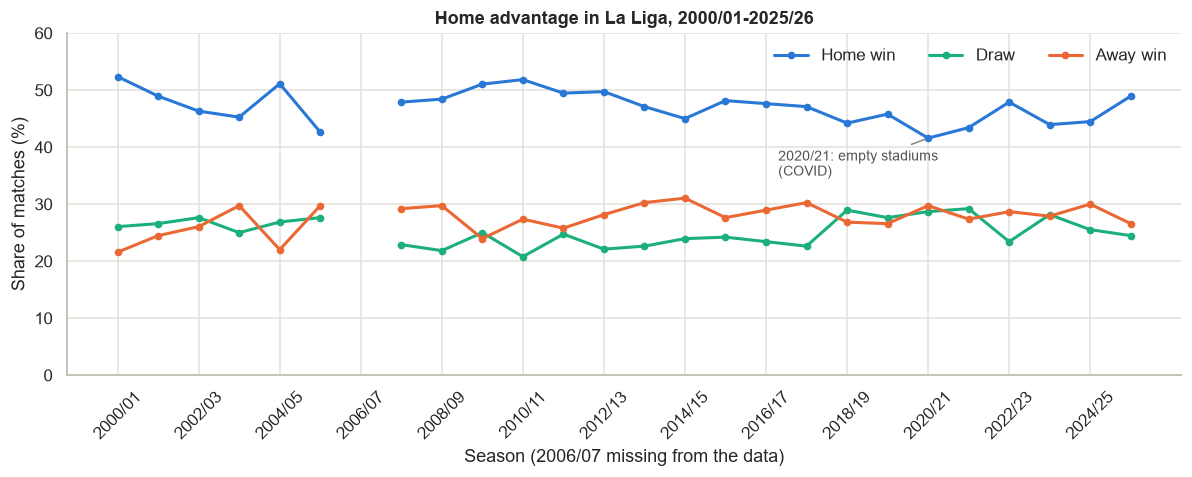

In [32]:
fig, ax = plt.subplots(figsize=(11, 4.5))

for result in RESULT_ORDER:
    ax.plot(
        result_share_by_season.index,
        result_share_by_season[result],
        color=RESULT_COLORS[result],
        linewidth=2,
        marker="o",
        markersize=4,
        label=RESULT_LABELS[result],
    )

# Label the one season played (almost entirely) without fans (COVID)
ax.annotate(
    "2020/21: empty stadiums\n(COVID)",
    xy=(2020, result_share_by_season.loc[2020, "H"]),
    xytext=(2016.3, 35),
    arrowprops={"arrowstyle": "-", "color": "#898781"},
    color="#52514e",
    fontsize=9,
)

set_season_xaxis(ax, all_seasons)
ax.set(
    title="Home advantage in La Liga, 2000/01-2025/26",
    xlabel="Season (2006/07 missing from the data)",
    ylabel="Share of matches (%)",
    ylim=(0, 60),
)
ax.legend(loc="upper right", frameon=False, ncols=3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "home_advantage_by_season.png")
plt.show()

In [33]:
# Overall result distribution across all complete seasons
(laliga_complete["FTResult"].value_counts(normalize=True)[RESULT_ORDER] * 100).round(1)

FTResult
H    47.2
D    25.2
A    27.7
Name: proportion, dtype: float64

In [34]:
# Average goals scored by the home and the away team per match, per season.
# Named aggregation: new_columns=(source_column, function)
goals_by_season = (
    laliga_complete.groupby("SeasonStart")
    .agg(home_goals=("FTHome", "mean"), away_goals=("FTAway", "mean"))
    .assign(total_goals=lambda df: df["home_goals"] + df["away_goals"])
    .reindex(all_seasons)  # Empty row for 2006/07, same as the above chart.
)
goals_by_season.round(2)  # Table version of the chart below

,home_goals,away_goals,total_goals
SeasonStart,,,
2000,1.77,1.11,2.88
2001,1.50,1.03,2.53
2002,1.55,1.12,2.67
2003,1.48,1.19,2.67
2004,1.54,1.05,2.59
2005,1.37,1.10,2.46
2006,NaN,NaN,NaN
2007,1.55,1.14,2.69
2008,1.66,1.24,2.90


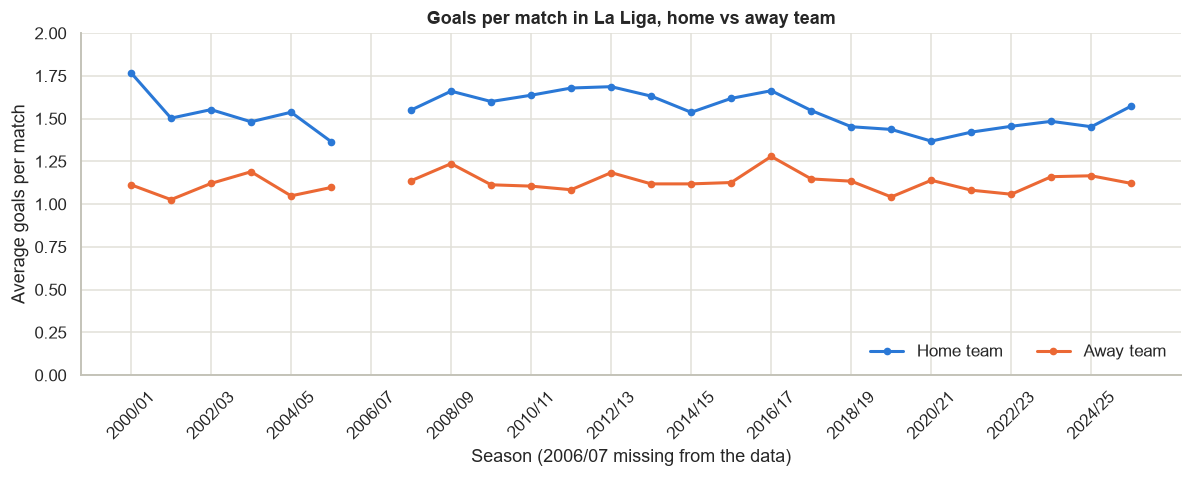

In [35]:
fig, ax = plt.subplots(figsize=(11, 4.5))

ax.plot(
    goals_by_season.index,
    goals_by_season["home_goals"],
    color=RESULT_COLORS["H"],
    linewidth=2,
    marker="o",
    markersize=4,
    label="Home team",
)

ax.plot(
    goals_by_season.index,
    goals_by_season["away_goals"],
    color=RESULT_COLORS["A"],
    linewidth=2,
    marker="o",
    markersize=4,
    label="Away team",
)

set_season_xaxis(ax, all_seasons)
ax.set(
    title="Goals per match in La Liga, home vs away team",
    xlabel="Season (2006/07 missing from the data)",
    ylabel="Average goals per match",
    ylim=(0, 2),
)
ax.legend(loc="lower right", frameon=False, ncols=2)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "goals_per_match_by_season.png")
plt.show()

In [36]:
# Averages over all complete seasons: The "typical match" baseline
overall_goals = laliga_complete[FULL_TIME_GOAL_COLUMNS].mean()
print(overall_goals.round(2))
print(f"Total goals per match: {overall_goals.sum():.2f}")

FTHome    1.55
FTAway    1.13
dtype: float64
Total goals per match: 2.67


### Findings

- Total goals per match ranges from **2.46** (2005/06) to **2.94** (2016/17).
- The blue home line clearly sits above the orange away line in every season.
- Home teams score about **0.42 more goals per match** (1.55 vs 1.13). In 2020/21, the Covid season, where games were played without fans, that gap fell to 0.23, which confirms what the results chart showed.

For the scoreline model, an average La Liga match looks like "home scores ~1.55, away ~1.13". That is why 1-0 and 1-1 will turn out to be the most common predicted scorelines.


Elo is a single number per team for its current strength, updated after every match. If it is useful, then the **bigger the gap between the two teams' Elo before kickoff, the more predictable the result should be**.

Note: This assumes `HomeElo` / `AwayElo` are pre-match ratings, meaning they don't already include the match's own result.

We will do that check at the start of feature engineering, before Elo goes into any model.


In [37]:
# Positive = home team rated stronger before kickoff, negative = away team stronger
elo_diff = (laliga_complete["HomeElo"] - laliga_complete["AwayElo"]).rename("EloDiff")
elo_diff.describe().round(1)

count    9388.0
mean        0.2
std       148.9
min      -495.1
25%       -84.2
50%         0.5
75%        84.6
max       471.0
Name: EloDiff, dtype: float64

In [38]:
# Group matches into 50-point bins of Elo difference. Values beyond ~400 are clipped into the outermost bins (only ~1% of matches on each side), so the extreme bins don't end up with a handful of matches each
ELO_BIN_WIDTH = 50
ELO_DIFF_LIMIT = 400

clipped_diff = elo_diff.clip(-ELO_DIFF_LIMIT, ELO_DIFF_LIMIT - 1)

# Floor to the bin's lower edge, then add half a bin: -130 --> -150 + 25 = -125
elo_bin_center = (
    (clipped_diff // ELO_BIN_WIDTH) * ELO_BIN_WIDTH + ELO_BIN_WIDTH / 2
).rename("EloDiffBin")

result_share_by_elo = (
    pd.crosstab(elo_bin_center, laliga_complete["FTResult"], normalize="index")[
        RESULT_ORDER
    ]
    * 100
)

# Table version of the chart, with the number of matches behind each point
result_share_by_elo.round(1).assign(n_matches=elo_bin_center.value_counts())

FTResult,H,D,A,n_matches
EloDiffBin,,,,
-375.0,12.5,18.5,69.0,168
-325.0,13.5,19.9,66.7,156
-275.0,19.5,23.9,56.6,205
-225.0,24.6,27.5,47.9,284
-175.0,24.0,28.7,47.3,425
-125.0,31.3,30.2,38.5,764
-75.0,37.5,28.1,34.4,1180
-25.0,44.4,28.2,27.4,1493
25.0,48.9,27.9,23.2,1527


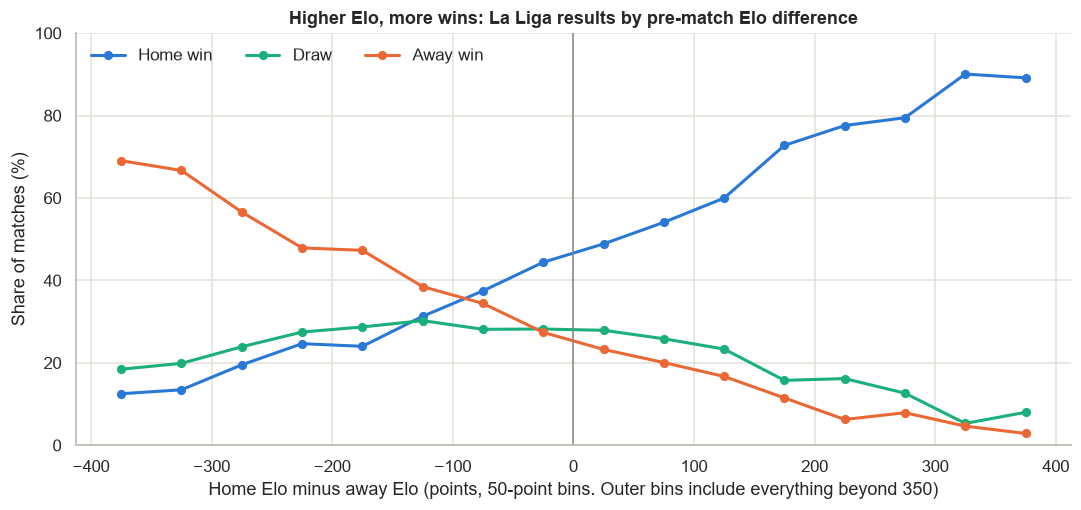

In [39]:
fig, ax = plt.subplots(figsize=(10, 4.8))

for result in RESULT_ORDER:
    ax.plot(
        result_share_by_elo.index,
        result_share_by_elo[result],
        color=RESULT_COLORS[result],
        linewidth=2,
        marker="o",
        markersize=5,
        label=RESULT_LABELS[result],
    )

ax.axvline(0, color="#898781", linewidth=1)  # Equally rated teams
ax.set(
    title="Higher Elo, more wins: La Liga results by pre-match Elo difference",
    xlabel="Home Elo minus away Elo (points, 50-point bins. Outer bins include everything beyond 350)",
    ylabel="Share of matches (%)",
    ylim=(0, 100),
)
ax.legend(loc="upper left", frameon=False, ncols=3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "results_by_elo_difference.png")
plt.show()

### Findings

- Home wins (blue) climb steadily from **12.5%** (home team ~375 points weaker) to ~**90%** (~325-375 points stronger).
- Away wins (orange) mirror that, from **69%** down to **3%**.
- Draws (aqua) form a gentle hump: ~**28-30% when the teams are close**, falling to **5-8% in big mismatches**.
- **Elo is strongly predictive.** The slope is steep and smooth, so `EloDiff` will be the core feature of the outcome model.
- **Home advantage is worth about 100 Elo points.** The home-win and away-win lines cross near **-100**, not at 0. A home team rated ~100 points weaker still wins as often as it loses. At equal ratings (the -25 and +25 bins), the home team wins 44-49% and loses only 23-27%.
- **This is why draws are hard to predict:** Even at their peak, in perfectly balanced matches, draws are only ~30%, never the most likely result. A model that always picks the most likely outcome will almost never predict a draw.


In [40]:
# Final league tables for La Liga and Segunda (EDA / Excel only)
team_seasons = build_team_season_table(spanish_clean)
laliga_tables = team_seasons[
    (team_seasons["Division"] == LALIGA_DIVISION)
    & (team_seasons["SeasonStart"] <= LAST_COMPLETE_SEASON)
]

print(f"team_seasons: {team_seasons.shape}, La Liga complete: {laliga_tables.shape}")
laliga_tables.head(3)

team_seasons: (1092, 14), La Liga complete: (500, 14)


,Division,SeasonStart,Season,Team,Played,Wins,Draws,Losses,GoalsFor,GoalsAgainst,GoalDiff,Points,PointsPerMatch,Rank
0,SP1,2000,2000/01,Real Madrid,38,24,8,6,81,40,41,80,2.105263,1
1,SP1,2000,2000/01,La Coruna,38,22,7,9,73,44,29,73,1.921053,2
2,SP1,2000,2000/01,Mallorca,38,20,11,7,61,43,18,71,1.868421,3


In [41]:
# Champions per season, and how often Real Madrid and Barcelona finished 1st and 2nd
champions = laliga_tables.loc[laliga_tables["Rank"] == 1, ["Season", "Team", "Points"]]
print(champions["Team"].value_counts())

big_two_in_top_two = (
    laliga_tables[laliga_tables["Rank"] <= 2]
    .groupby("SeasonStart")["Team"]
    .apply(lambda teams: set(teams) == set(BIG_TWO_COLORS))
)

print(
    f"Real Madrid and Barcelona finished 1st and 2nd in "
    f"{big_two_in_top_two.sum()} of {len(big_two_in_top_two)} seasons"
)

Team
Barcelona      13
Real Madrid     8
Valencia        2
Ath Madrid      2
Name: count, dtype: int64
Real Madrid and Barcelona finished 1st and 2nd in 16 of 25 seasons


In [42]:
# Points per match per season: Each big club, plus the best of the other 18
is_big_two = laliga_tables["Team"].isin(BIG_TWO_COLORS)
best_other_ppm = (
    laliga_tables[~is_big_two]
    .groupby("SeasonStart")["PointsPerMatch"]
    .max()
    .reindex(all_seasons)
)

big_two_ppm = (
    laliga_tables[is_big_two]
    .pivot_table(index="SeasonStart", columns="Team", values="PointsPerMatch")
    .reindex(all_seasons)
)

big_two_ppm.assign(best_other=best_other_ppm).round(2)  # Table version of the chart

Team,Barcelona,Real Madrid,best_other
SeasonStart,,,
2000,1.66,2.11,1.92
2001,1.68,1.74,1.97
2002,1.47,2.05,2.00
2003,1.89,1.84,2.03
2004,2.30,2.07,1.81
2005,2.16,1.84,1.82
2006,NaN,NaN,NaN
2007,1.76,2.24,2.03
2008,2.29,2.05,1.84


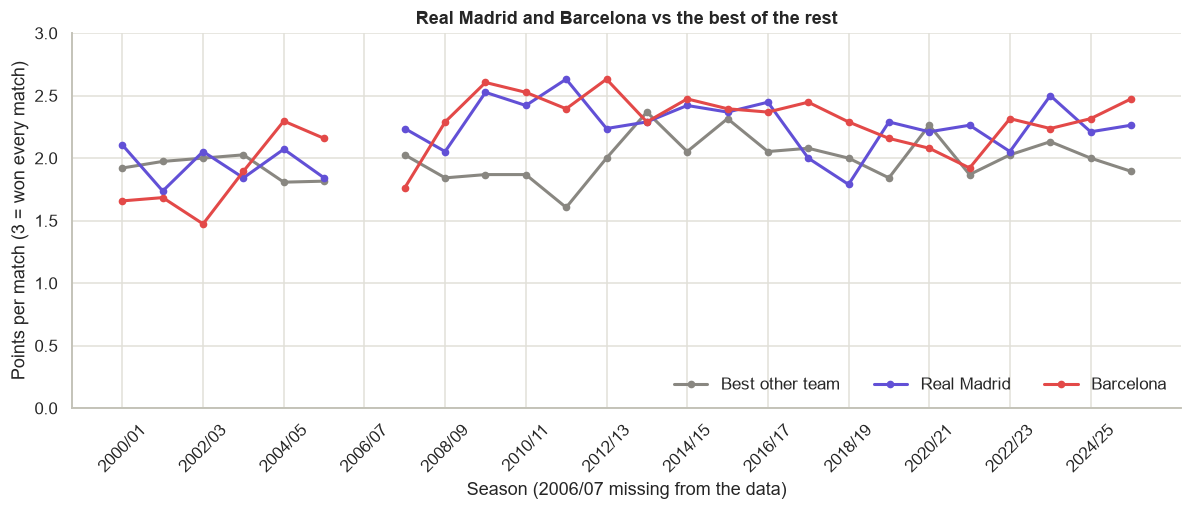

In [43]:
fig, ax = plt.subplots(figsize=(11, 4.8))

ax.plot(
    best_other_ppm.index,
    best_other_ppm,
    color=OTHER_TEAMS_COLOR,
    linewidth=2,
    marker="o",
    markersize=4,
    label="Best other team",
)

for team, color in BIG_TWO_COLORS.items():
    ax.plot(
        big_two_ppm.index,
        big_two_ppm[team],
        color=color,
        linewidth=2,
        marker="o",
        markersize=4,
        label=team,
    )

set_season_xaxis(ax, all_seasons)
ax.set(
    title="Real Madrid and Barcelona vs the best of the rest",
    xlabel="Season (2006/07 missing from the data)",
    ylabel="Points per match (3 = won every match)",
    ylim=(0, 3),
)

ax.legend(loc="lower right", frameon=False, ncols=3)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "big_two_dominance.png")
plt.show()

### Findings

- **Champions:** Barcelona **13**, Real Madrid **8**, Valencia 2, Ath Madrid 2.
- **Top two:** `Real Madrid and Barcelona finished 1st and 2nd in 16 of 25 seasons`.
- **The Chart:** From 2007/08 onwards, Real Madrid (violet) and Barcelona (red) mostly sit at **2.2-2.6 points per match**, well above the Best other team (grey), which mostly sits at 1.85-2.1.
- The two clubs won **21 of 25 titles** (84%) and averaged ~**2.2 points per match**, against **1.28** for everyone else. For the model, matches involving them are much more predictable. They're usually heavy favorites.


### EDA summary: what the data tells us before modeling

1. **Home advantage is large and stable.** Home teams win 47.2% of La Liga matches, draws are 25.2% and away wins 27.7%. Home teams score 1.55 goals per match against 1.13 for away teams. The clearest exception is **2020/21, played without fans**. Home wins dropped to their lowest level (41.6%) and the home–away goal gap shrank to 0.23, from 0.42 on average. Crowds are part of home advantage.
2. **Pre-match Elo difference is strongly predictive.** Home win rates climb smoothly from 12.5% (home team ~375 points weaker) to ~90% (~325 – 375 points stronger), with away wins mirroring that. The home-win and away-win lines cross between the −125 and −75 bins, so **home advantage is worth roughly 100 Elo points**. Elo difference will be the core feature of the outcome model.
3. **Draws are hard to predict.** Even in evenly matched games they peak at only ~28 – 30%, and they're never the most likely result. A model that always picks its top outcome will rarely predict a draw, which is why we judge models on probability quality (log loss, Brier score) rather than accuracy alone.
4. **La Liga is a two-club league.** Barcelona (13) and Real Madrid (8) won 21 of 25 titles, finished 1st and 2nd in 16 of 25 seasons, and averaged 2.21 and 2.19 points per match against 1.28 for all other teams. Their matches should be easier to predict, so the evaluation reports them separately.
5. **The scoreline baseline is about 1.55–1.13.** An average match produces 2.67 goals. The model will adjust each side's expected goals per match using team strength and form.

**Data caveats behind these charts:** 2006/07 is missing from the source (visible as gaps), 2004/05 is incomplete (268 of 380 matches), and the in-progress 2026/27 season is excluded.


## Excel export

Export the cleaned La Liga matches and the league tables to `outputs/laliga_data.xlsx`.
The Excel analysis (season statistics, charts, pivot tables, lookups and conditional formatting) is built on top of this data in `outputs/laliga_analysis.xlsx`.


In [44]:
# Only the columns the Excel analysis needs
EXCEL_MATCH_COLUMNS = [
    "Season",
    "SeasonStart",
    "MatchDate",
    "HomeTeam",
    "AwayTeam",
    "FTHome",
    "FTAway",
    "FTResult",
    "HomeElo",
    "AwayElo",
    "OddHome",
    "OddDraw",
    "OddAway",
]

EXCEL_TABLE_COLUMNS = [
    "Season",
    "SeasonStart",
    "Rank",
    "Team",
    "Played",
    "Wins",
    "Draws",
    "Losses",
    "GoalsFor",
    "GoalsAgainst",
    "GoalDiff",
    "Points",
    "PointsPerMatch",
]

# Complete La Liga seasons only
excel_sheets = {
    "Matches": laliga_complete[EXCEL_MATCH_COLUMNS],
    "TeamSeasons": laliga_tables[EXCEL_TABLE_COLUMNS],
}

In [45]:
with pd.ExcelWriter(EXCEL_DATA_PATH, engine="openpyxl") as writer:
    excel_sheets["Matches"].assign(
        MatchDate=lambda df: df["MatchDate"].dt.date
    ).to_excel(writer, sheet_name="Matches", index=False, freeze_panes=(1, 0))

    excel_sheets["TeamSeasons"].to_excel(
        writer, sheet_name="TeamSeasons", index=False, freeze_panes=(1, 0)
    )

for sheet_name, sheet_df in excel_sheets.items():
    print(f"{sheet_name}: {sheet_df.shape}")

print(f"Saved to {EXCEL_DATA_PATH.relative_to(REPO_ROOT)}")

Matches: (9388, 13)
TeamSeasons: (500, 13)
Saved to outputs\laliga_data.xlsx


In [46]:
# Read every sheet back and check it equals what we exported.
excel_read_back = pd.read_excel(EXCEL_DATA_PATH, sheet_name=None)

for sheet_name, exported_df in excel_sheets.items():
    pd.testing.assert_frame_equal(
        excel_read_back[sheet_name],
        exported_df.reset_index(drop=True),
        check_dtype=False,
    )
    print(f"{sheet_name}: {excel_read_back[sheet_name].shape} identical to the export")

Matches: (9388, 13) identical to the export
TeamSeasons: (500, 13) identical to the export


## Feature engineering

### Leakage check: Are Elo and Form pre-match?

A feature for a match may only use information from before kickoff. The dataset's Elo and Form columns could have been computed _including_ the match's own result, which would leak the answer into the model. We test this by reshaping the data to one row per team per match and checking what each value react to.


In [47]:
# One row per team per match, in date order per team.
team_matches = build_team_matches(spanish_clean)

print(f"team_matches: {team_matches.shape}")
team_matches.head(3)

team_matches: (40822, 19)


,MatchId,Division,SeasonStart,Season,MatchDate,Team,Opponent,Elo,Form3,Form5,GoalsFor,GoalsAgainst,ShotsFor,ShotsAgainst,TargetFor,TargetAgainst,IsHome,Points,Outcome
0,18,SP1,2000,2000/01,2000-09-10,Alaves,Las Palmas,1773.97,0.0,0.0,3,0,NaN,NaN,NaN,NaN,False,3,W
1,39,SP1,2000,2000/01,2000-09-17,Alaves,Villarreal,1787.98,9.0,15.0,0,1,NaN,NaN,NaN,NaN,True,0,L
2,57,SP1,2000,2000/01,2000-09-23,Alaves,Zaragoza,1787.98,5.0,8.0,2,2,NaN,NaN,NaN,NaN,False,1,D


In [48]:
# A pre-match Elo reacts to a result only in the team's next row. If Elo included the match's own result, which is a leakage, then wins would already show a rise into this row.
by_team = team_matches.groupby("Team")

elo_check = team_matches.assign(
    EloChangeBefore=team_matches["Elo"] - by_team["Elo"].shift(1),
    EloChangeAfter=by_team["Elo"].shift(-1) - team_matches["Elo"],
)

(
    elo_check[elo_check["Division"] == LALIGA_DIVISION]
    .groupby("Outcome")[["EloChangeBefore", "EloChangeAfter"]]
    .mean()
    .loc[["W", "D", "L"]]
    .round(2)
)

,EloChangeBefore,EloChangeAfter
Outcome,,
W,-0.12,3.87
D,0.08,-0.03
L,-0.06,-4.13


In [49]:
# Recompute Form from the results. Points from each team's previous n matches.
# shift(1) moves every value down one row, so each row only sees earlier matches.
for n in [3, 5]:
    points_before = (
        by_team["Points"]
        .transform(lambda points: points.shift(1).rolling(n, min_periods=1).sum())
        .fillna(0)
    )

    points_including = by_team["Points"].transform(
        lambda points: points.rolling(n, min_periods=1).sum()
    )

    form = team_matches[f"Form{n}"]
    has_form = form.notna()

    print(
        f"Form{n}: equals points from the previous {n} matches in "
        f"{(form[has_form] == points_before[has_form]).mean():.1%} of rows, "
        f"points including this match in "
        f"{(form[has_form] == points_including[has_form]).mean():.1%}"
    )

Form3: equals points from the previous 3 matches in 99.7% of rows, points including this match in 35.1%
Form5: equals points from the previous 5 matches in 99.3% of rows, points including this match in 34.9%


In [50]:
# Form3 should equal the points of the three rows above it, and Elo should move in the row after each result
spot_check = team_matches.assign(
    PointsPrev3=by_team["Points"].transform(
        lambda points: points.shift(1).rolling(3, min_periods=1).sum()
    ),
    EloNext=by_team["Elo"].shift(-1),
)

SPOT_CHECK_COLUMNS = [
    "MatchDate",
    "Opponent",
    "IsHome",
    "GoalsFor",
    "GoalsAgainst",
    "Points",
    "Form3",
    "PointsPrev3",
    "Elo",
    "EloNext",
]

is_real_madrid = (spot_check["Team"] == "Real Madrid") & (
    spot_check["Season"] == "2025/26"
)
spot_check.loc[is_real_madrid, SPOT_CHECK_COLUMNS].head(8)

,MatchDate,Opponent,IsHome,GoalsFor,GoalsAgainst,Points,Form3,PointsPrev3,Elo,EloNext
29222,2025-08-19,Osasuna,True,1,0,3,9.0,9.0,1936.13,1939.17
29223,2025-08-24,Oviedo,False,3,0,3,9.0,9.0,1939.17,1942.07
29224,2025-08-30,Mallorca,True,2,1,3,9.0,9.0,1942.07,1944.25
29225,2025-09-13,Sociedad,False,2,1,3,9.0,9.0,1944.25,1948.48
29226,2025-09-20,Espanol,True,2,0,3,9.0,9.0,1948.48,1950.96
29227,2025-09-23,Levante,False,4,1,3,9.0,9.0,1950.96,1954.14
29228,2025-09-27,Ath Madrid,False,2,5,0,9.0,9.0,1954.14,1942.52
29229,2025-10-04,Villarreal,True,3,1,3,6.0,6.0,1942.52,1947.40


### Findings

- **Elo:** The rating changes _after_ a match in line with its result, while the change _into_ the match row is about 0 whatever the result. The rating is taken before kickoff, so it is safe as a feature.
- **Form3 / Form5:** They equal the points from the team's previous 3 / 5 matches in 99.7% / 99.3% of rows, against about 35% if the current match were included. Also pre-match and safe.
- **Form carries over seasons and divisions:** A team's first match of a season uses the end of its previous season, and a promoted team's form comes from its Segunda matches.


### Rolling team features

For each team and match, the average goals and conceded, and shots on target for and against, over the team's previous `ROLLING_WINDOW` matches.
`shift(1)` before `rolling()` keeps the current match out of its own feature. The window carries over between seasons, but only La Liga matches count. Segunda stats come against weaker opponents.


In [51]:
team_matches = add_rolling_averages(
    team_matches,
    ROLLING_COLUMNS,
    ROLLING_WINDOW,
    ROLLING_MIN_PERIODS,
    division=LALIGA_DIVISION,
)

ROLLING_FEATURES = [f"{column}Avg{ROLLING_WINDOW}" for column in ROLLING_COLUMNS]

print(f"team_matches: {team_matches.shape}")
team_matches[ROLLING_FEATURES].describe().round(2)

team_matches: (40822, 23)


,GoalsForAvg10,GoalsAgainstAvg10,TargetForAvg10,TargetAgainstAvg10
count,18812.00,18812.00,15221.00,15221.00
mean,1.34,1.34,4.33,4.34
std,0.55,0.44,1.22,1.00
min,0.00,0.10,1.60,1.40
25%,1.00,1.00,3.50,3.60
50%,1.20,1.30,4.10,4.30
75%,1.60,1.60,4.90,5.00
max,4.30,4.00,10.50,9.20


In [52]:
# Real Madrid vs Villarreal (2025-10-04): The feature should equal the mean of the 10 rows above it, not the window that includes this match
real_madrid = team_matches[team_matches["Team"] == "Real Madrid"].reset_index(drop=True)
row = real_madrid.index[real_madrid["MatchDate"] == "2025-10-04"][0]

print(
    f"TargetForAvg10 in the Villarreal row:       {real_madrid.loc[row, 'TargetForAvg10']:.1f}"
)
print(
    f"Mean of the 10 previous matches:            {real_madrid.loc[row - 10 : row - 1, 'TargetFor'].mean():.1f}"
)
print(
    f"Mean including the Villarreal match itself: {real_madrid.loc[row - 9 : row, 'TargetFor'].mean():.1f}"
)

real_madrid.loc[
    row - 10 : row, ["MatchDate", "Opponent", "TargetFor", "TargetForAvg10"]
]

TargetForAvg10 in the Villarreal row:       7.2
Mean of the 10 previous matches:            7.2
Mean including the Villarreal match itself: 6.6


,MatchDate,Opponent,TargetFor,TargetForAvg10
899,2025-05-14,Mallorca,13.0,6.0
900,2025-05-18,Sevilla,6.0,7.1
901,2025-05-24,Sociedad,8.0,7.2
902,2025-08-19,Osasuna,5.0,7.5
903,2025-08-24,Oviedo,10.0,7.0
904,2025-08-30,Mallorca,7.0,7.1
905,2025-09-13,Sociedad,6.0,7.4
906,2025-09-20,Espanol,5.0,7.3
907,2025-09-23,Levante,10.0,7.1
908,2025-09-27,Ath Madrid,2.0,7.5


In [53]:
# Missing rolling values in the La Liga seasons we will model (2007/08 onward)
in_model_seasons = (team_matches["Division"] == LALIGA_DIVISION) & (
    team_matches["SeasonStart"] >= FIRST_MODEL_SEASON
)

missing_rolling = team_matches.loc[in_model_seasons, ROLLING_FEATURES].isna()

print(missing_rolling.sum())

team_matches.loc[in_model_seasons & missing_rolling["TargetForAvg10"]].groupby(
    "Season"
).size()

GoalsForAvg10         304
GoalsAgainstAvg10     304
TargetForAvg10        304
TargetAgainstAvg10    304
dtype: int64


Season
2007/08    25
2008/09    15
2009/10    15
2010/11    15
2011/12    15
2012/13    15
2013/14    15
2014/15    15
2015/16    15
2016/17    15
2017/18    15
2018/19    15
2019/20    15
2020/21    15
2021/22    15
2022/23    15
2023/24    15
2024/25    15
2025/26    15
2026/27     9
dtype: int64

### Promoted teams

A promoted team's rolling averages need La Liga history it doesn't have yet. Its Segunda stats can't stand in for it, because they come against weaker opponents. The check below compares the same teams in their last Segunda season and their first La Liga season.


In [54]:
team_matches = add_promoted_flag(team_matches, LALIGA_DIVISION)

# Promoted teams per season (should be 3, except 2007/08)
# The 2006/07 season is missing, so the two clubs promoted into 2006/07 also look promoted in 2007/08)
(
    team_matches.loc[team_matches["IsPromoted"], ["Season", "Team"]]
    .drop_duplicates()
    .groupby("Season")["Team"]
    .agg(", ".join)
    .tail(4)
)

Season
2023/24     Alaves, Granada, Las Palmas
2024/25    Espanol, Leganes, Valladolid
2025/26          Elche, Levante, Oviedo
2026/27    La Coruna, Malaga, Santander
Name: Team, dtype: str

In [55]:
# Teams promoted from 2018/19 to 2025/26. Their last Segunda season has shot stats (SP2 stats start in 2017/18), and their first La Liga season is complete
promoted_team_seasons = team_matches.loc[
    team_matches["IsPromoted"]
    & team_matches["SeasonStart"].between(2018, TEST_SEASON_START),
    ["Team", "SeasonStart"],
].drop_duplicates()

last_segunda_seasons = promoted_team_seasons.assign(
    SeasonStart=promoted_team_seasons["SeasonStart"] - 1
)

# The same 24 teams in both seasons. Average per-match stats by division
(
    pd.concat([last_segunda_seasons, promoted_team_seasons])
    .merge(team_matches, on=["Team", "SeasonStart"])
    .groupby("Division")[ROLLING_COLUMNS]
    .mean()
    .round(2)
)

,GoalsFor,GoalsAgainst,TargetFor,TargetAgainst
Division,,,,
SP1,1.04,1.55,3.51,4.65
SP2,1.38,0.89,4.26,3.32


In [56]:
# Until a promoted team has ROLLING_MIN_PERIODS La Liga matches, use the average promoted team's rolling values (the "prior"). Computed on training seasons only, so the test season can't influence it
is_train_promoted = team_matches["IsPromoted"] & (
    team_matches["SeasonStart"] < TEST_SEASON_START
)

promoted_prior = team_matches.loc[is_train_promoted, ROLLING_FEATURES].mean()

uses_prior = (
    in_model_seasons
    & team_matches["IsPromoted"]
    & team_matches[ROLLING_FEATURES].isna().any(axis=1)
)

team_matches.loc[uses_prior, ROLLING_FEATURES] = team_matches.loc[
    uses_prior, ROLLING_FEATURES
].fillna(promoted_prior)

print(f"Rows filled with the promoted-team prior: {uses_prior.sum()}")
print(
    "Missing rolling values left in the model seasons: "
    f"{team_matches.loc[in_model_seasons, ROLLING_FEATURES].isna().sum().sum()}"
)

promoted_prior.round(2)

Rows filled with the promoted-team prior: 304
Missing rolling values left in the model seasons: 0


GoalsForAvg10         1.06
GoalsAgainstAvg10     1.53
TargetForAvg10        3.71
TargetAgainstAvg10    4.78
dtype: float64

### Findings: promoted teams

- Promoted teams look much stronger in Segunda than they are in La Liga. The same teams concede 0.89 goals per match in their last Segunda season and 1.55 in their first La Liga season. So rolling stats count La Liga matches only.
- A promoted team's first 5 La Liga matches use the average promoted team's values (the prior), computed on training seasons only. That's 304 team-match rows, 15 per season.
- Trade-off: the prior treats every promoted team as typical for its first 5 matches. Elo and Form, which span both divisions, still tell the model whether it's a strong or a weak promoted team.
- Within the training data, the prior uses all training seasons. For example, a 2008/09 row is filled with a value that includes 2020s teams. That's a mild in-sample shortcut. The test season (2025/26) only ever sees a prior computed from earlier seasons.


### Model table: one row per match

Each La Liga match from 2007/08 to 2025/26 gets the pre-match features of both teams side by side (`Home*` and `Away*` columns), plus `EloDiff`, the home team's Elo minus the away team's.


In [57]:
# Team-level columns to bring back to the match. Elo and Form are already in the match columns (HomeElo, Form5Home, ...)
TEAM_FEATURE_COLUMNS = ROLLING_FEATURES + ["IsPromoted"]

is_model_match = (spanish_clean["Division"] == LALIGA_DIVISION) & spanish_clean[
    "SeasonStart"
].between(FIRST_MODEL_SEASON, LAST_COMPLETE_SEASON)

model_matches = add_team_features(
    spanish_clean[is_model_match], team_matches, TEAM_FEATURE_COLUMNS
).assign(EloDiff=lambda df: df["HomeElo"] - df["AwayElo"])

print(f"model_matches: {model_matches.shape}")

model_matches: (7220, 54)


In [58]:
# Same match as the rolling hand check. Real Madrid's TargetForAvg10 was 7.2
MODEL_CHECK_COLUMNS = [
    "MatchDate",
    "HomeTeam",
    "AwayTeam",
    "EloDiff",
    "HomeTargetForAvg10",
    "AwayTargetForAvg10",
    "HomeIsPromoted",
    "AwayIsPromoted",
]

is_check_match = (model_matches["HomeTeam"] == "Real Madrid") & (
    model_matches["MatchDate"] == "2025-10-04"
)

model_matches.loc[is_check_match, MODEL_CHECK_COLUMNS]

,MatchDate,HomeTeam,AwayTeam,EloDiff,HomeTargetForAvg10,AwayTargetForAvg10,HomeIsPromoted,AwayIsPromoted
19660,2025-10-04,Real Madrid,Villarreal,136.75,7.2,5.6,False,False


In [59]:
# Every pre-match input the models may use, plus the targets and the odds benchmark
CANDIDATE_FEATURES = [
    "EloDiff",
    "HomeElo",
    "AwayElo",
    "Form3Home",
    "Form3Away",
    "Form5Home",
    "Form5Away",
] + [f"{side}{feature}" for side in ["Home", "Away"] for feature in ROLLING_FEATURES]

print(f"Missing feature values: {model_matches[CANDIDATE_FEATURES].isna().sum().sum()}")
print(
    f"Missing targets: {model_matches[['FTResult', 'FTHome', 'FTAway']].isna().sum().sum()}"
)
print(
    f"Missing odds: {model_matches[['OddHome', 'OddDraw', 'OddAway']].isna().sum().sum()}"
)

Missing feature values: 0
Missing targets: 0
Missing odds: 0


### Train / test split by season

We train on 2007/08–2024/25 and test on 2025/26, the most recent complete season. Splitting by time mimics real use: the model always predicts matches _after_ everything it learned from. A random split would mix future matches into training. Choices such as feature selection are tuned with forward-chaining CV inside the training seasons, so the test season is used once, at the end.


In [60]:
is_train = model_matches["SeasonStart"] < TEST_SEASON_START
train_matches = model_matches[is_train]
test_matches = model_matches[~is_train]

print(
    f"Train: {len(train_matches)} matches, {train_matches['Season'].min()} to {train_matches['Season'].max()}"
)

print(f"Test:  {len(test_matches)} matches, {test_matches['Season'].min()}")

# Result shares in each set. The "always home win" baseline and the class frequencies baseline come from these numbers
pd.DataFrame(
    {
        "train": train_matches["FTResult"].value_counts(normalize=True),
        "test": test_matches["FTResult"].value_counts(normalize=True),
    }
).loc[RESULT_ORDER].mul(100).round(1)

Train: 6840 matches, 2007/08 to 2024/25
Test:  380 matches, 2025/26


,train,test
FTResult,,
H,46.9,48.9
D,24.8,24.5
A,28.3,26.6


## Modeling

### Baselines

Before any model, we score four simple predictors on the test season, so every later score has a reference:

- **Uniform:** 1/3 for each result. It knows nothing, so it's the floor.
- **Always home win:** 100% on a home win.
- **Training frequencies:** The share of home wins, draws and away wins in the training seasons, the same for every match.
- **Bookmaker (Bet365):** The odds converted to probabilities, the strong benchmark. Odds are _only_ a benchmark, never a model feature: the goal is to see how close public pre-match data gets to the market.

**Metrics:**

- **Log loss** (main metric): The average −ln(probability given to the actual result). It rewards honest probabilities and punishes confident mistakes hard.
- **Brier score:** The squared distance between the probabilities and the result, from 0 (perfect) to 2.
- **Accuracy:** How often the most likely result happened.

Log loss and Brier score judge the _probabilities_, which is what we want to show users. Accuracy only checks the top pick.


In [61]:
# 1 / odds gives the implied chance of each result. Their sum is above 100%:
# The excess is the bookmaker's margin, which bookmaker_probabilities removes
implied_total = (1 / test_matches[list(ODDS_COLUMNS.values())]).sum(axis=1)

print(f"Average bookmaker margin in the test season: {implied_total.mean() - 1:.1%}")

bookmaker_test = bookmaker_probabilities(test_matches)

test_matches[["HomeTeam", "AwayTeam", *ODDS_COLUMNS.values(), "FTResult"]].join(
    bookmaker_test.round(3)
).head(3)

Average bookmaker margin in the test season: 5.6%


,HomeTeam,AwayTeam,OddHome,OddDraw,OddAway,FTResult,H,D,A
19505,Girona,Vallecano,2.25,3.25,3.3,A,0.421,0.292,0.287
19506,Villarreal,Oviedo,1.40,4.75,8.0,H,0.680,0.201,0.119
19510,Mallorca,Barcelona,7.00,5.00,1.4,A,0.135,0.189,0.676


In [62]:
train_frequencies = train_matches["FTResult"].value_counts(normalize=True)

# Each baseline: One row of H/D/A probabilities per test match. A dict of scalars with an index repeats the same values on every row
baselines = {
    "Uniform (1/3 each)": pd.DataFrame(
        {"H": 1 / 3, "D": 1 / 3, "A": 1 / 3}, index=test_matches.index
    ),
    "Always home win": pd.DataFrame(
        {"H": 1.0, "D": 0.0, "A": 0.0}, index=test_matches.index
    ),
    "Training frequencies": pd.DataFrame(
        train_frequencies.to_dict(), index=test_matches.index
    ),
    "Bookmaker (Bet365)": bookmaker_test,
}

baseline_scores = pd.DataFrame(
    {
        name: score_probabilities(test_matches["FTResult"], probabilities)
        for name, probabilities in baselines.items()
    }
).T

baseline_scores.round(4)

,log_loss,brier,accuracy
Uniform (1/3 each),1.0986,0.6667,0.2658
Always home win,18.4012,1.0211,0.4895
Training frequencies,1.0473,0.6306,0.4895
Bookmaker (Bet365),0.9637,0.5710,0.5447


In [63]:
# How often is each result the bookmaker's most likely one, vs how often it happened?
pd.DataFrame(
    {
        "most_likely": bookmaker_test.idxmax(axis=1).value_counts(),
        "actual": test_matches["FTResult"].value_counts(),
    }
).reindex(RESULT_ORDER).fillna(0).astype(int)

,most_likely,actual
H,280,186
D,0,93
A,100,101


### Findings: baselines

- **The bookmakers are the bar to beat:** Log loss 0.964 on 2025/26, against 1.047 for "same probabilities for every match" and 1.099 for knowing nothing. The gap between 1.047 and 0.964 is the value of knowing _who is playing_. Our model has to earn its place inside that gap.
- **Accuracy is misleading here.** "Always home win" and the training frequencies both score 48.9% accuracy, yet one is useless (log loss 18.4) and the other is reasonable (1.047).
- **Draws are never the favorite.** Even the bookmakers make a draw the most likely result in 0 of 380 matches, although 93 matches (24.5%) ended in a draw. A draw is rarely more likely than _both_ wins, so any model that picks the top result will almost never predict a draw. This is why we judge probabilities, not picks.
- The bookmaker's margin averages 5.6% per match. We remove it by normalizing the implied probabilities to sum to 100%.


### Logistic regression: Choosing the features

The outcome model is a multinomial logistic regression. It turns the features of a match into three probabilities (home win, draw, away win) that add up to 100%. We picked it because it is simple, fast, and every feature gets a weight we can read and explain.

To choose the features, we compare five feature sets with forward chaining validation. For each season from 2015/16 to 2024/25, we train on all earlier seasons and score on that season. The test season (2025/26) is not used here.


In [64]:
# Rolling features of each team, as model columns
SHOT_FEATURES = [
    "HomeTargetForAvg10",
    "HomeTargetAgainstAvg10",
    "AwayTargetForAvg10",
    "AwayTargetAgainstAvg10",
]

GOAL_FEATURES = [
    "HomeGoalsForAvg10",
    "HomeGoalsAgainstAvg10",
    "AwayGoalsForAvg10",
    "AwayGoalsAgainstAvg10",
]

FORM_FEATURES = ["Form5Home", "Form5Away"]

FEATURE_SETS = {
    "Elo": ["EloDiff"],
    "Elo + form": ["EloDiff", *FORM_FEATURES],
    "Elo + shots on target": ["EloDiff", *SHOT_FEATURES],
    "Elo + shots on target + goals": ["EloDiff", *SHOT_FEATURES, *GOAL_FEATURES],
    "All": ["EloDiff", *FORM_FEATURES, *SHOT_FEATURES, *GOAL_FEATURES],
}

cv_scores = pd.DataFrame(
    {
        name: forward_chaining_log_loss(train_matches, features, CV_SEASONS)
        for name, features in FEATURE_SETS.items()
    }
)

# The bookmaker on the same seasons, as a reference
cv_scores["Bookmaker"] = [
    score_probabilities(
        train_matches.loc[train_matches["SeasonStart"] == season, "FTResult"],
        bookmaker_probabilities(train_matches[train_matches["SeasonStart"] == season]),
    )["log_loss"]
    for season in CV_SEASONS
]

# Average log loss over the 10 validation seasons (lower is better)
cv_scores.mean().sort_values().round(4)

Bookmaker                        0.9639
Elo + shots on target            0.9778
All                              0.9788
Elo + shots on target + goals    0.9791
Elo                              0.9814
Elo + form                       0.9823
dtype: float64

### Logistic regression: Final model

"Elo + shots on target" has the lowest validation log loss, and it beats Elo alone in 7 of 10 seasons. Form and rolling goals add nothing once Elo is in the model: Elo already captures results, while shots on target add new information about how teams play. We train this model on all training seasons and score it on the test season for the first time.


In [65]:
FEATURES = FEATURE_SETS["Elo + shots on target"]

outcome_model = make_outcome_model().fit(
    train_matches[FEATURES], train_matches["FTResult"]
)

logistic_test = predict_outcomes(outcome_model, test_matches, FEATURES)

# Add the model to the baseline table
model_scores = baseline_scores.copy()
model_scores.loc["Logistic regression"] = score_probabilities(
    test_matches["FTResult"], logistic_test
)

model_scores.round(4)

,log_loss,brier,accuracy
Uniform (1/3 each),1.0986,0.6667,0.2658
Always home win,18.4012,1.0211,0.4895
Training frequencies,1.0473,0.6306,0.4895
Bookmaker (Bet365),0.9637,0.5710,0.5447
Logistic regression,0.9667,0.5722,0.5316


In [66]:
# How much of the gap between "knows nothing about the teams" and the bookmaker does the model close?
log_losses = model_scores["log_loss"]
gap_closed = (
    log_losses["Training frequencies"] - log_losses["Logistic regression"]
) / (log_losses["Training frequencies"] - log_losses["Bookmaker (Bet365)"])

print(f"The model closes {gap_closed:.0%} of the gap to the bookmaker")

The model closes 96% of the gap to the bookmaker


## Evaluation

### Train vs test

If the model scored much better on the training seasons than on the test season, it would be memorizing the training data (overfitting).


In [67]:
logistic_train = predict_outcomes(outcome_model, train_matches, FEATURES)

pd.DataFrame(
    {
        "train": score_probabilities(train_matches["FTResult"], logistic_train),
        "test": score_probabilities(test_matches["FTResult"], logistic_test),
    }
).T.round(4)

,log_loss,brier,accuracy
train,0.9675,0.5748,0.5348
test,0.9667,0.5722,0.5316


### What the model learned

The coefficients show how each feature moves the chance of each result. The features are scaled, so a coefficient is the effect of one standard deviation: About 160 Elo points, or about 1 shot on target per match. A positive value makes that result more likely.


In [68]:
logistic = outcome_model.named_steps["logisticregression"]

# One row per feature, one column per result
coefficients = pd.DataFrame(
    logistic.coef_.T, index=FEATURES, columns=logistic.classes_
)[RESULT_ORDER]

coefficients.round(3)

,H,D,A
EloDiff,0.486,-0.035,-0.450
HomeTargetForAvg10,0.100,-0.090,-0.010
HomeTargetAgainstAvg10,-0.039,-0.001,0.040
AwayTargetForAvg10,-0.025,-0.063,0.088
AwayTargetAgainstAvg10,0.066,-0.027,-0.040


In [69]:
# We vary the Elo difference and keep every shots column at its training average
what_if = pd.DataFrame({"EloDiff": [-200, -100, 0, 100, 200]}).assign(
    **train_matches[SHOT_FEATURES].mean()
)

what_if[["EloDiff"]].join(predict_outcomes(outcome_model, what_if, FEATURES).round(3))

,EloDiff,H,D,A
0,-200,0.257,0.279,0.464
1,-100,0.359,0.281,0.360
2,0,0.471,0.266,0.263
3,100,0.582,0.237,0.181
4,200,0.682,0.200,0.118


### Findings: Coefficients

- **Elo is by far the strongest feature.** Each 100 Elo points in favor of the home team add about 11 points to its win chance. Between equal teams (Elo difference 0), the home team still wins 47% of the time: That is home advantage, learned by the model's intercept.
- **The away team needs about 100 more Elo points just to make it an even match** (36% vs 36% at a difference of minus 100).
- **Shots on target mostly move draws.** A home team that creates many shots raises its win chance and _lowers the draw chance_ (minus 0.090). The same holds for the away team (minus 0.063). Teams that create a lot of chances play more open matches, which end level less often.


### Confusion matrix and draws

The confusion matrix counts the model's top pick (the result with the highest probability) against what actually happened.


In [70]:
pd.crosstab(
    test_matches["FTResult"],
    logistic_test.idxmax(axis=1),
    rownames=["Actual"],
    colnames=["Predicted"],
).reindex(index=RESULT_ORDER, columns=RESULT_ORDER, fill_value=0)

# fill_value=0 adds the "D" column because the model never picks a draw, so that column wouldn't exist otherwise

Predicted,H,D,A
Actual,,,
H,159,0,27
D,62,0,31
A,58,0,43


In [71]:
# Average predicted probability of each result vs how often it happened
pd.DataFrame(
    {
        "model_average": logistic_test.mean(),
        "bookmaker_average": bookmaker_test.mean(),
        "actual_share": test_matches["FTResult"].value_counts(normalize=True),
    }
).loc[RESULT_ORDER].mul(100).round(1)

,model_average,bookmaker_average,actual_share
H,46.8,44.4,48.9
D,24.7,26.0,24.5
A,28.5,29.7,26.6


### Findings: Draws

- **The model never picks a draw (0 of 380), and neither do the bookmakers.** A draw is almost never more likely than both a home win and an away win.
- **But the model does not ignore draws.** Its average draw probability is 24.7%, and 24.5% of matches were draws. The draw chance is in the probabilities, not in the top pick. This is why accuracy alone is misleading.


### Calibration

When the model says 60%, does it happen about 60% of the time? We put every predicted probability (3 per match, 1,140 in total) into 10 groups of the same size. For each group, we compare the average prediction with how often that result happened. A well calibrated model stays close to the diagonal.


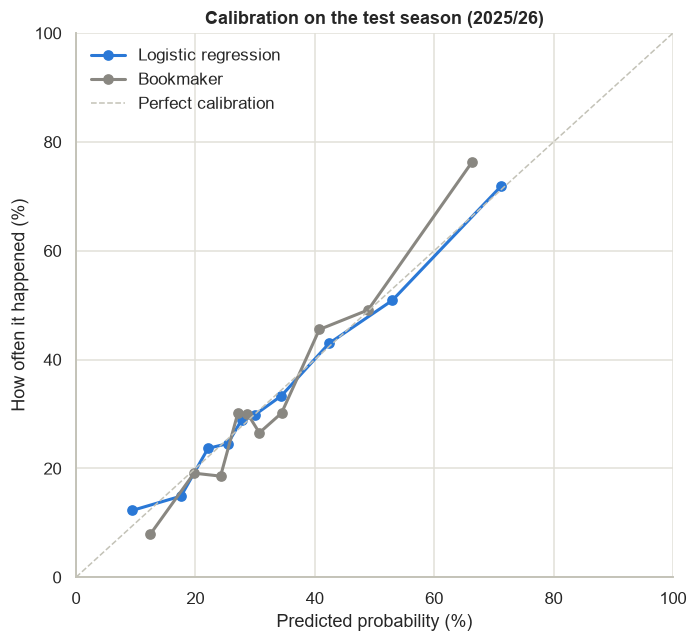

In [72]:
# One 0 / 1 column per result: Did this result happen? Same column order as the probabilities, so .ravel() lines up each prediction with its outcome
happened = pd.get_dummies(test_matches["FTResult"])[RESULT_ORDER]

fig, ax = plt.subplots(figsize=(6.5, 6))

for name, probabilities, color in [
    ("Logistic regression", logistic_test, RESULT_COLORS["H"]),
    ("Bookmaker", bookmaker_test, OTHER_TEAMS_COLOR),
]:
    actual_share, predicted_average = calibration_curve(
        happened.to_numpy().ravel(),
        probabilities[RESULT_ORDER].to_numpy().ravel(),
        n_bins=10,
        strategy="quantile",
    )

    # strategy="quantile" makes groups with the same number of predictions.

    ax.plot(
        predicted_average * 100,
        actual_share * 100,
        color=color,
        linewidth=2,
        marker="o",
        label=name,
    )

ax.plot(
    [0, 100],
    [0, 100],
    color="#c3c2b7",
    linestyle="--",
    linewidth=1,
    label="Perfect calibration",
)

ax.set(
    title="Calibration on the test season (2025/26)",
    xlabel="Predicted probability (%)",
    ylabel="How often it happened (%)",
    xlim=(0, 100),
    ylim=(0, 100),
)

ax.legend(loc="upper left", frameon=False)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "calibration_test_season.png")
plt.show()

### Real Madrid and Barcelona vs the rest


In [73]:
involves_big_two = test_matches["HomeTeam"].isin(BIG_TWO_COLORS) | test_matches[
    "AwayTeam"
].isin(BIG_TWO_COLORS)

split_scores = {}

for group, is_group in [
    ("Real Madrid or Barcelona", involves_big_two),
    ("Other matches", ~involves_big_two),
]:
    for name, probabilities in [
        ("Logistic regression", logistic_test),
        ("Bookmaker", bookmaker_test),
    ]:
        split_scores[(group, name)] = score_probabilities(
            test_matches.loc[is_group, "FTResult"], probabilities[is_group]
        )

print(f"Matches with Real Madrid or Barcelona: {involves_big_two.sum()}")

pd.DataFrame(split_scores).T.round(4)

Matches with Real Madrid or Barcelona: 74


log_loss   brier  accuracy
Real Madrid or Barcelona Logistic regression    0.6897  0.3709    0.7838
                         Bookmaker              0.6882  0.3747    0.7838
Other matches            Logistic regression    1.0337  0.6209    0.4706
                         Bookmaker              1.0303  0.6185    0.4869

### Findings: Evaluation

- **No overfitting:** Train and test scores are almost equal (log loss 0.9675 vs 0.9667).
- **Well calibrated:** When the model gives a result about 70%, it happens about 70% of the time. Its probabilities can be shown to users as they are.
- **Close to the bookmakers:** Log loss 0.9667 vs 0.9637. The model closes 96% of the gap between "same probabilities for every match" and the bookmaker, using only public data from before kickoff.
- **Matches with Real Madrid or Barcelona are much easier:** Log loss 0.69 vs 1.03 for the other matches, and 78% accuracy. Here the model equals the bookmaker (even a slightly better Brier score). The other matches are where football is hard to predict, and where the bookmaker keeps its edge.


### Scoreline model: Two Poisson regressions

To predict a score, we model goals. A Poisson regression predicts the expected number of goals (for example 1.6), and the Poisson distribution turns it into the chance of 0, 1, 2, ... goals. We fit one model for the home team's goals and one for the away team's goals, with the same five features.

If the two teams' goals are independent, P(2:1) = P(home scores 2) × P(away scores 1). Doing this for every score gives the score matrix.


In [74]:
home_goals_model = make_goals_model().fit(
    train_matches[FEATURES], train_matches["FTHome"]
)

away_goals_model = make_goals_model().fit(
    train_matches[FEATURES], train_matches["FTAway"]
)

expected_goals_test = pd.DataFrame(
    {
        "ExpectedHome": home_goals_model.predict(test_matches[FEATURES]),
        "ExpectedAway": away_goals_model.predict(test_matches[FEATURES]),
    },
    index=test_matches.index,
)

# Check: The average expected goals should be close to the real averages
pd.DataFrame(
    {
        "predicted": expected_goals_test.mean().to_numpy(),
        "actual": test_matches[FULL_TIME_GOAL_COLUMNS].mean().to_numpy(),
    },
    index=["Home goals", "Away goals"],
).round(2)

,predicted,actual
Home goals,1.55,1.57
Away goals,1.14,1.12


In [75]:
test_matrices = score_matrices(
    expected_goals_test["ExpectedHome"], expected_goals_test["ExpectedAway"], MAX_GOALS
)

print(f"Score matrices: {test_matrices.shape}")

# Example: Real Madrid vs Villarreal (2025-10-04), the match from the rolling check
is_example = (test_matches["HomeTeam"] == "Real Madrid") & (
    test_matches["MatchDate"] == "2025-10-04"
)

example_position = np.flatnonzero(is_example)[0]  # Row number of the match
expected_goals_test[is_example].round(2)

Score matrices: (380, 9, 9)


,ExpectedHome,ExpectedAway
19660,2.31,0.96


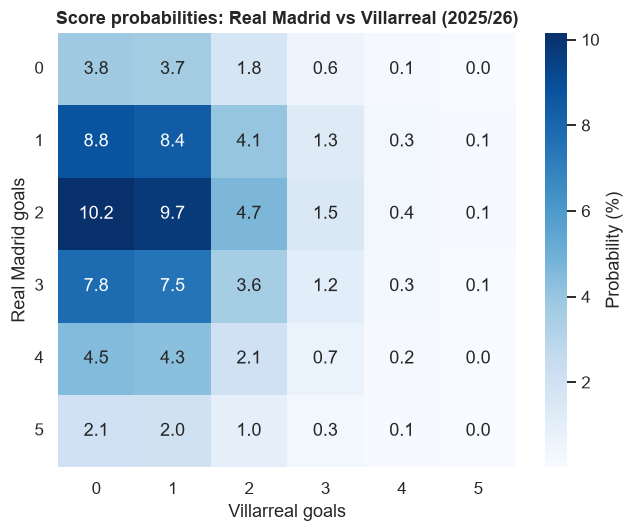

In [76]:
# The top left corner of the example's score matrix (0 to 5 goals each)
fig, ax = plt.subplots(figsize=(6, 5))

sns.heatmap(
    pd.DataFrame(test_matrices[example_position, :6, :6]).mul(100),
    annot=True,
    fmt=".1f",
    cmap="Blues",
    cbar_kws={"label": "Probability (%)"},
    ax=ax,
)

ax.set(
    title="Score probabilities: Real Madrid vs Villarreal (2025/26)",
    xlabel="Villarreal goals",
    ylabel="Real Madrid goals",
)

ax.tick_params(axis="y", rotation=0)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "score_matrix_example.png")
plt.show()

In [77]:
poisson_test = outcomes_from_scores(test_matrices, test_matches.index)
test_scores = most_likely_scores(test_matrices, test_matches.index)

# The example match: H/D/A from the three sources
pd.DataFrame(
    {
        "Poisson": poisson_test.loc[is_example].iloc[0],
        "Logistic regression": logistic_test.loc[is_example].iloc[0],
        "Bookmaker": bookmaker_test.loc[is_example].iloc[0],
    }
).T.round(3)

,H,D,A
Poisson,0.676,0.183,0.142
Logistic regression,0.713,0.150,0.137
Bookmaker,0.653,0.189,0.158


In [78]:
model_scores.loc["Poisson (H/D/A from the score matrix)"] = score_probabilities(
    test_matches["FTResult"], poisson_test
)

model_scores.round(4)

,log_loss,brier,accuracy
Uniform (1/3 each),1.0986,0.6667,0.2658
Always home win,18.4012,1.0211,0.4895
Training frequencies,1.0473,0.6306,0.4895
Bookmaker (Bet365),0.9637,0.5710,0.5447
Logistic regression,0.9667,0.5722,0.5316
Poisson (H/D/A from the score matrix),0.9683,0.5740,0.5289


In [79]:
print(
    f"Average draw probability: Poisson {poisson_test['D'].mean():.1%}, "
    f"logistic {logistic_test['D'].mean():.1%}, "
    f"actual share {(test_matches['FTResult'] == 'D').mean():.1%}"
)

is_exact_score = (test_scores["ScoreHome"] == test_matches["FTHome"]) & (
    test_scores["ScoreAway"] == test_matches["FTAway"]
)

print(
    "Average probability of the most likely score: "
    f"{test_scores['ScoreProbability'].mean():.1%}"
)

print(
    f"The most likely score was the actual score in {is_exact_score.mean():.1%} "
    f"of matches ({is_exact_score.sum()} of {len(test_matches)})"
)

# Which scores come out as "most likely"?
test_scores.value_counts(["ScoreHome", "ScoreAway"])

Average draw probability: Poisson 23.6%, logistic 24.7%, actual share 24.5%
Average probability of the most likely score: 12.5%
The most likely score was the actual score in 15.3% of matches (58 of 380)


ScoreHome  ScoreAway
1          1            187
           0             99
2          0             41
0          1             24
           2             14
3          0             13
1          2              1
2          1              1
Name: count, dtype: int64

### Findings: Scoreline model

- **The expected goals are right on average:** 1.55 home and 1.14 away goals per match, against 1.57 and 1.12 in reality.
- **An exact score is never likely.** The most likely score has on average a 12.5% chance. It was the real score in 15.3% of matches. So we always show the score _with_ its probability, and the headline is the H / D / A probability.
- **1:1 is the most likely score in about half of the matches.** For close matches, a draw score is the single most likely cell, even when a home win is more likely overall. A home win is spread over many cells (1:0, 2:0, 2:1, ...), and a draw over only a few.
- **Poisson H / D / A is slightly worse than the logistic regression** (log loss 0.9683 vs 0.9667) and gives fewer draws (23.6% vs 24.5% real). This is a known weakness: Real goals are not fully independent, because teams play more carefully at level scores. So we use the logistic regression for the H / D / A probabilities and the Poisson matrix only for the score.


## Example predictions: The rest of 2026/27

The dataset has no future fixtures, so we build them: Every team plays every other team at home and away, minus the matches already played. There are no kickoff dates for these pairings.


In [80]:
current_season = spanish_clean[
    (spanish_clean["Division"] == LALIGA_DIVISION)
    & (spanish_clean["SeasonStart"] == LAST_COMPLETE_SEASON + 1)
]

current_teams = sorted(
    set(current_season["HomeTeam"]) | set(current_season["AwayTeam"])
)

# Every (home, away) pair of two different teams
all_pairings = pd.DataFrame(
    itertools.permutations(current_teams, 2), columns=["HomeTeam", "AwayTeam"]
)

# Keep the pairs that are not in the played matches.
# indicator=True adds a _merge column that says if a row was found on both sides or only on the left
remaining_pairings = (
    all_pairings.merge(
        current_season[["HomeTeam", "AwayTeam"]], how="left", indicator=True
    )
    .query("_merge == 'left_only'")
    .drop(columns="_merge")
    .reset_index(drop=True)
)

print(
    f"Teams: {len(current_teams)}, all pairings: {len(all_pairings)}, "
    f"played: {len(current_season)}, remaining: {len(remaining_pairings)}"
)

Teams: 20, all pairings: 380, played: 31, remaining: 349


Each team's current state: Its latest Elo rating (the newest snapshot in EloRatings.csv) and its rolling averages over its last 10 matches, now including the most recent one. Promoted teams without 5 La Liga matches get the promoted team prior.


In [81]:
latest_elo_date = elo["date"].max()

latest_elo = elo.loc[
    (elo["date"] == latest_elo_date) & (elo["country"] == "ESP")
].set_index("club")["elo"]

team_state = latest_rolling_averages(
    team_matches,
    ROLLING_COLUMNS,
    ROLLING_WINDOW,
    ROLLING_MIN_PERIODS,
    division=LALIGA_DIVISION,
).loc[current_teams]

print(
    "Teams without enough La Liga matches: "
    f"{team_state[team_state.isna().any(axis=1)].index.tolist()}"
)

team_state = team_state.fillna(promoted_prior).assign(Elo=latest_elo)

print(
    f"Elo snapshot: {latest_elo_date.date()}, missing values: {team_state.isna().sum().sum()}"
)

team_state.sort_values("Elo", ascending=False).round(2).head(3)

Teams without enough La Liga matches: ['La Coruna', 'Malaga', 'Santander']
Elo snapshot: 2026-09-01, missing values: 0


,GoalsForAvg10,GoalsAgainstAvg10,TargetForAvg10,TargetAgainstAvg10,Elo
Team,,,,,
Barcelona,2.3,0.8,5.7,2.6,1970.35
Real Madrid,2.2,0.8,6.5,3.5,1932.27
Ath Madrid,1.8,1.5,4.3,4.7,1815.89


In [82]:
# Put both teams' state next to each pairing, like the model table
fixtures = (
    remaining_pairings.join(team_state.add_prefix("Home"), on="HomeTeam")
    .join(team_state.add_prefix("Away"), on="AwayTeam")
    .assign(EloDiff=lambda df: df["HomeElo"] - df["AwayElo"])
)

print(f"fixtures: {fixtures.shape}")

fixtures: (349, 13)


The test season has done its job. For real predictions, we refit the same models on all 19 seasons (2007/08 to 2025/26), so they also learn from the most recent season. The test scores above stay the honest measure of quality.


In [83]:
outcome_model_final = make_outcome_model().fit(
    model_matches[FEATURES], model_matches["FTResult"]
)

home_goals_model_final = make_goals_model().fit(
    model_matches[FEATURES], model_matches["FTHome"]
)

away_goals_model_final = make_goals_model().fit(
    model_matches[FEATURES], model_matches["FTAway"]
)

fixture_matrices = score_matrices(
    home_goals_model_final.predict(fixtures[FEATURES]),
    away_goals_model_final.predict(fixtures[FEATURES]),
    MAX_GOALS,
)

# H / D / A from the logistic regression, the score from the Poisson matrix
upcoming_predictions = (
    fixtures[["HomeTeam", "AwayTeam"]]
    .join(predict_outcomes(outcome_model_final, fixtures, FEATURES))
    .join(most_likely_scores(fixture_matrices, fixtures.index))
)

upcoming_predictions["Prediction"] = [
    f"{row.HomeTeam} {row.H:.0%} / Draw {row.D:.0%} / {row.AwayTeam} {row.A:.0%}, "
    f"most likely {row.ScoreHome}-{row.ScoreAway} ({row.ScoreProbability:.0%})"
    for row in upcoming_predictions.itertuples()
]

# Real Madrid's remaining home matches
is_real_madrid_home = upcoming_predictions["HomeTeam"] == "Real Madrid"

print("\n".join(upcoming_predictions.loc[is_real_madrid_home, "Prediction"].head(5)))

Real Madrid 79% / Draw 13% / Alaves 8%, most likely 2-0 (12%)
Real Madrid 79% / Draw 13% / Ath Bilbao 8%, most likely 2-0 (12%)
Real Madrid 69% / Draw 17% / Ath Madrid 14%, most likely 2-0 (11%)
Real Madrid 46% / Draw 22% / Barcelona 32%, most likely 1-1 (12%)
Real Madrid 75% / Draw 14% / Betis 11%, most likely 2-0 (11%)


In [84]:
# The most lopsided and the closest pairings
most_lopsided = upcoming_predictions[["H", "A"]].max(axis=1).nlargest(3).index
closest = upcoming_predictions[["H", "A"]].max(axis=1).nsmallest(3).index

# print the strings themselves: pandas shortens text longer than 50 characters
print("Most lopsided:")
print("\n".join(upcoming_predictions.loc[most_lopsided, "Prediction"]))
print("\nClosest:")
print("\n".join(upcoming_predictions.loc[closest, "Prediction"]))

Most lopsided:
Barcelona 88% / Draw 9% / Malaga 3%, most likely 3-0 (13%)
Barcelona 87% / Draw 10% / La Coruna 4%, most likely 3-0 (13%)
Barcelona 86% / Draw 10% / Santander 4%, most likely 2-0 (13%)

Closest:
Malaga 34% / Draw 32% / Celta 34%, most likely 1-1 (13%)
Malaga 34% / Draw 31% / Sevilla 35%, most likely 1-1 (13%)
Celta 35% / Draw 30% / Betis 36%, most likely 1-1 (13%)


In [85]:
is_clasico = upcoming_predictions["HomeTeam"].isin(
    BIG_TWO_COLORS
) & upcoming_predictions["AwayTeam"].isin(BIG_TWO_COLORS)

print("\n".join(upcoming_predictions.loc[is_clasico, "Prediction"]))

Barcelona 55% / Draw 20% / Real Madrid 25%, most likely 1-1 (11%)
Real Madrid 46% / Draw 22% / Barcelona 32%, most likely 1-1 (12%)


### Findings: Example predictions

- The model predicts all 349 remaining pairings of 2026/27 in the app format: "Team X 58% / Draw 24% / Team Y 18%, most likely 2:1 (12%)".
- The clearest favorite is Barcelona at home against a promoted team (86% to 88%). The closest pairings are between mid table teams, with all three results near one third.
- El Clásico at the Bernabéu: Real Madrid 46% / Draw 22% / Barcelona 32%. At Camp Nou: Barcelona 55% / Draw 20% / Real Madrid 25%. Home advantage swings about 9 points, even between the two strongest teams.
- The most likely score is never above about 15%, which is honest: Exact scores are hard to predict.
- Elo after June 2025 is the dataset's provisional continuation, not official ClubElo, and the snapshot is from 2026-09-01. So Sociedad's and Celta's ratings don't include their matches of 2026-09-03.


### Export predictions to Excel

Two more sheets go into the data workbook (laliga_data.xlsx): The test season predictions next to the actual results, and the predictions for the remaining 2026/27 pairings. The analysis workbook uses them for a predictions vs actual sheet.


In [86]:
test_predictions = (
    test_matches[
        ["Season", "MatchDate", "HomeTeam", "AwayTeam", "FTHome", "FTAway", "FTResult"]
    ]
    .join(logistic_test.add_prefix("Model"))
    .join(bookmaker_test.add_prefix("Bookmaker"))
    .join(test_scores)
    .assign(ModelPick=logistic_test.idxmax(axis=1))
)

prediction_sheets = {
    "TestPredictions": test_predictions.assign(
        MatchDate=lambda df: df["MatchDate"].dt.date  # Dates without a time
    ),
    "UpcomingPredictions": upcoming_predictions,
}

# Append to the data workbook. The two sheets from the Excel export section stay
with pd.ExcelWriter(
    EXCEL_DATA_PATH, engine="openpyxl", mode="a", if_sheet_exists="replace"
) as writer:
    for sheet_name, sheet_df in prediction_sheets.items():
        sheet_df.to_excel(
            writer, sheet_name=sheet_name, index=False, freeze_panes=(1, 0)
        )

print(
    f"Sheets in {EXCEL_DATA_PATH.name}: {list(pd.read_excel(EXCEL_DATA_PATH, sheet_name=None))}"
)

for sheet_name, sheet_df in prediction_sheets.items():
    print(f"{sheet_name}: {sheet_df.shape}")

Sheets in laliga_data.xlsx: ['Matches', 'TeamSeasons', 'TestPredictions', 'UpcomingPredictions']
TestPredictions: (380, 17)
UpcomingPredictions: (349, 9)
